In [13]:
%matplotlib inline
import sys
import h5py
import numpy as np
import torch
from torch.utils.data import ConcatDataset, DataLoader
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, AutoMinorLocator
from scipy.optimize import curve_fit
from sklearn.metrics import roc_curve, auc

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
})

sys.path.append("/data/condor_shared/users/nmanic/RNO_machine_learning/RNO_classifier/classifier_consistency/train_eval")

from train_benchmark import ARCH_REGISTRY, WaveformDataset
from evaluate_comparison import get_scores, threshold_at_fpr

ckpt_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/runs/exp01/best_model.pt"

# Variables for choosing plotting data
signal_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/nu/nu_extracted.hdf5"
noise_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/noise/noise_extracted.hdf5"
target_fpr = 1e-3
# Set compare to True if signal & noise files aren't what the model was trained on
compare = False
batch_size = 512

device = (torch.device("cuda") if torch.cuda.is_available() else
              torch.device("mps")  if torch.backends.mps.is_available() else
              torch.device("cpu"))

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
cfg  = ckpt.get("config", {})

model = ARCH_REGISTRY[cfg.get("arch", "baseline")](n_channels=4).to(device)
model.load_state_dict(ckpt["model_state"])

if "sig_val_idx" not in ckpt or "noi_val_idx" not in ckpt:
        sys.exit(
            "ERROR: checkpoint does not contain val indices.\n"
            "Re-run step2_train.py to produce a new checkpoint, then evaluate again."
        )
sig_val_idx = ckpt["sig_val_idx"]
noi_val_idx = ckpt["noi_val_idx"]

if compare:
    with h5py.File(signal_path, "r") as f:
        sig_val_idx = np.arange(f["waveforms"].shape[0])
    with h5py.File(noise_path,  "r") as f:
        noi_val_idx = np.arange(f["waveforms"].shape[0])
    print(f"Comparison mode: using all {len(sig_val_idx)} signal "
        f"and {len(noi_val_idx)} noise events")

crop = cfg.get("crop_samples", None)
val_ds = ConcatDataset([
    WaveformDataset(signal_path, sig_val_idx, crop),
    WaveformDataset(noise_path,  noi_val_idx, crop),
])
loader = DataLoader(val_ds, batch_size=batch_size,
                    shuffle=False, num_workers=4, persistent_workers=True,
                    pin_memory=(device.type == "cuda"))

# ── inference ─────────────────────────────────────────────────────────────
scores, val_labels = get_scores(model, loader, device)

# Gather SNR for signal val events (from HDF5 directly)
with h5py.File(signal_path, "r") as f:
    sig_snr_all = f["snr"][:]          # (N_sig, 4)
    trigger_scores_all = f["triggered"][:] if "triggered" in f else None # (N_sig,)

sig_snr_val = sig_snr_all[sig_val_idx]
if trigger_scores_all is not None:
    print('Found triggered dataset, will plot this as well for comparison')
    trigger_scores_val = trigger_scores_all[sig_val_idx]
    noise_trigger_val = np.zeros(len(noi_val_idx), dtype=np.int8)
    trigger_scores_val = np.concatenate([trigger_scores_val, noise_trigger_val], axis=0)
else:
    print('Did not find triggered dataset')
    trigger_scores_val = None
    
# Pad noise SNR with NaN so arrays align with val_labels
noise_snr_val = np.full((len(noi_val_idx), 4), float("nan"), dtype=np.float32)
snr_val = np.concatenate([sig_snr_val, noise_snr_val], axis=0)
# nanmax gives NaN for all-NaN rows (noise events); replace with 0 for plotting
snr_per_event = np.where(
    np.all(np.isnan(snr_val), axis=1),
    0.0,
    np.nanmax(snr_val, axis=1),
)

# ── ROC + threshold ───────────────────────────────────────────────────────
fpr_arr, tpr_arr, thresholds = roc_curve(val_labels, scores, pos_label=1)
roc_auc = auc(fpr_arr, tpr_arr)
threshold, op_fpr, op_tpr = threshold_at_fpr(
    fpr_arr, tpr_arr, thresholds, target_fpr)

Found triggered dataset, will plot this as well for comparison


/tmp/ipykernel_1971727/904981866.py:96: RuntimeWarning: All-NaN slice encountered
  np.nanmax(snr_val, axis=1),


/tmp/ipykernel_1971727/1882644752.py:51: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(8, 4))


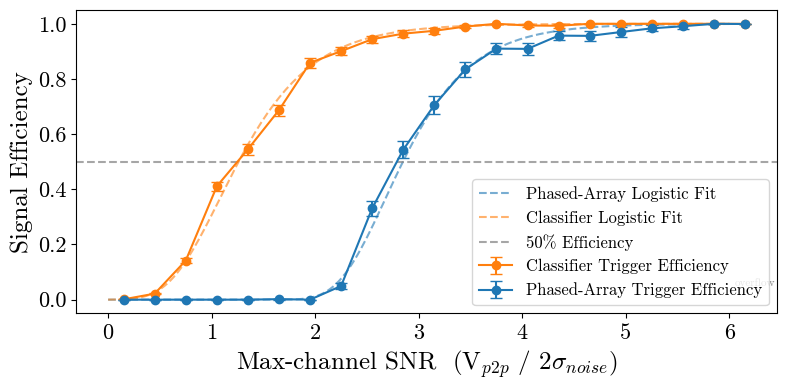

In [14]:
sig_mask   = val_labels == 1
sig_scores = scores[sig_mask]
sig_trigger_scores = trigger_scores_val[sig_mask] if trigger_scores_val is not None else None
sig_snr    = snr_per_event[sig_mask]
snr_max = 6.0
n_bins = 20

# Linear bins up to snr_max, then one overflow bin
bin_edges = np.linspace(0, snr_max, n_bins + 1)
all_edges = np.append(bin_edges, np.inf)
centres   = 0.5 * (bin_edges[:-1] + bin_edges[1:])
centres   = np.append(centres, snr_max + 0.5 * snr_max / n_bins)  # overflow centre

effs, errs, counts = [], [], []
for lo, hi in zip(all_edges[:-1], all_edges[1:]):
    mask  = (sig_snr >= lo) & (sig_snr < hi)
    n_tot = mask.sum()
    if n_tot == 0:
        effs.append(np.nan); errs.append(0.0); counts.append(0)
        continue
    n_pass = (sig_scores[mask] >= threshold).sum()
    eff    = n_pass / n_tot
    effs.append(eff)
    errs.append(np.sqrt(eff * (1 - eff) / n_tot))
    counts.append(n_tot)

effs   = np.array(effs)
errs   = np.array(errs)
counts = np.array(counts)
valid  = counts > 0

if sig_trigger_scores is not None:
    trigger_effs, trigger_errs, trigger_counts = [], [], []
    for lo, hi in zip(all_edges[:-1], all_edges[1:]):
        mask  = (sig_snr >= lo) & (sig_snr < hi)
        n_tot = mask.sum()
        if n_tot == 0:
            trigger_effs.append(np.nan); trigger_errs.append(0.0); trigger_counts.append(0)
            continue
        n_pass = (sig_trigger_scores[mask] >= threshold).sum()
        eff    = n_pass / n_tot
        trigger_effs.append(eff)
        trigger_errs.append(np.sqrt(eff * (1 - eff) / n_tot))
        trigger_counts.append(n_tot)

    trigger_effs   = np.array(trigger_effs)
    trigger_errs   = np.array(trigger_errs)
    trigger_counts = np.array(trigger_counts)
    trigger_valid  = trigger_counts > 0

fig, ax = plt.subplots(figsize=(8, 4))

ax.errorbar(centres[valid], effs[valid], yerr=errs[valid],
            fmt="o-", capsize=4, label="Classifier Trigger Efficiency", color='tab:orange')
if trigger_scores_val is not None:
    ax.errorbar(centres[trigger_valid], trigger_effs[trigger_valid], yerr=trigger_errs[trigger_valid],
            fmt="o-", capsize=4, label="Phased-Array Trigger Efficiency", color='tab:blue')

# logistic fit
def fit(x, x0, k, nu):
    return 1 / (1+np.exp(-k * (x - x0)))**(1/nu)

fit_mask=valid & (errs > 0)
popt,pcov=curve_fit(
    fit, centres[fit_mask], effs[fit_mask],
    p0=[2.0, 1.0, 1.0],
    sigma=errs[fit_mask],
    absolute_sigma=True,
)
x0_fit, k_fit, nu_fit = popt
x0_err, k_err, nu_err = np.sqrt(np.diag(pcov))
snr_at_50_fit = x0_fit + (1/k_fit) * np.log(2**nu_fit - 1)
snr_bins = np.linspace(0, snr_max, 200)

if trigger_scores_val is not None:
    trigger_fit_mask = trigger_valid & (trigger_errs > 0)
    trigger_popt, trigger_pcov = curve_fit(
        fit, centres[trigger_fit_mask], trigger_effs[trigger_fit_mask],
        p0=[2.0, 1.0, 1.0],
        sigma=trigger_errs[trigger_fit_mask],
        absolute_sigma=True,
    )
    trigger_x0_fit, trigger_k_fit, trigger_nu_fit = trigger_popt
    trigger_x0_err, trigger_k_err, trigger_nu_err = np.sqrt(np.diag(trigger_pcov))
    trigger_snr_at_50_fit = trigger_x0_fit + (1/trigger_k_fit) * np.log(2**trigger_nu_fit - 1)

    ax.plot(snr_bins, fit(snr_bins, *trigger_popt), '--', color='tab:blue', alpha=.6, lw=1.5, label="Phased-Array Logistic Fit")

labelsize=18

ax.plot(snr_bins, fit(snr_bins, *popt), '--', color='tab:orange', alpha=.6, lw=1.5, label=f"Classifier Logistic Fit")

ax.axhline(0.5, ls="--", color="gray", alpha=0.7, label="50% Efficiency")
ax.text(snr_max + 0.05, 0.05, "overflow", fontsize=8, color="gray")
ax.set_xlabel(r"Max-channel SNR  (V$_{p2p}$ / 2$\sigma_{noise}$)", fontsize=labelsize)
ax.set_ylabel("Signal Efficiency", fontsize=labelsize)
ax.set_xlim=(0, snr_max * 1.15)
ax.tick_params(axis='both', which='major', labelsize=16)
ax.set_ylim=(-0.05, 1.05)

#ax.grid(True, alpha=.5)
# ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
# ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
# ax.xaxis.set_minor_locator(AutoMinorLocator(2))
# ax.yaxis.set_minor_locator(AutoMinorLocator(2))
# ax.grid(True, which='major', linestyle='-', linewidth=0.6, alpha=.7)
# ax.grid(True, which='minor', linestyle=':', linewidth=0.4, alpha=.7)

lines1,labs1=ax.get_legend_handles_labels()
ax.legend(lines1, labs1, loc='lower right', fontsize=12)

fig.tight_layout()
plt.show()

# Interpolate values to get 50% efficiency SNR
snr_at_50=np.interp(.5, effs[valid], centres[valid])